# Exploratory Data Analysis on Retail Sales Data

**Objective:** Explore a retail sales dataset to uncover sales patterns, customer behaviour trends, and actionable business insights.

**Dataset:** Retail Sales Dataset (Mohammad Talib, Kaggle)

**Tools:** Python, pandas, matplotlib, seaborn

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# Load the dataset
df = pd.read_csv("retail_sales_dataset.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape: (1000, 9)
Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 1. Data Loading and Initial Inspection

In [26]:
print("Shape:", df.shape)
print("\n--- Column Data Types ---")
print(df.dtypes)

print("\n--- Null Values per Column ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print(df.duplicated().sum())

print("\n--- Dataset Info ---")
df.info()

Shape: (1000, 9)

--- Column Data Types ---
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

--- Null Values per Column ---
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

--- Duplicate Rows ---
0

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000

In [27]:
df["Date"] = pd.to_datetime(df["Date"])
print(df["Date"].dtype)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

datetime64[ns]
Date range: 2023-01-01 00:00:00 to 2024-01-01 00:00:00


Observations:
The dataset has 1,000 transactions and 9 columns. Five are numeric (Transaction ID, Age, Quantity, Price per Unit, Total Amount) and four are text (Date, Customer ID, Gender, Product Category).
There are no missing values in any column, so no imputation or row deletion is needed.
There are no duplicate rows.
The Date column was stored as text, so I converted it to datetime. This is needed for the monthly and quarterly trend analysis later.
The data covers 1 January 2023 to 1 January 2024. That's one full year plus a single extra day, so I'll need to keep this in mind when looking at monthly totals (January 2024 will have only one day of data).

## 2. Descriptive Statistics

In [28]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Std Dev": df[num_cols].std(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max()
}).round(2)

stats

,Mean,Median,Mode,Std Dev,Min,Max
Age,41.39,42.0,43.0,13.68,18,64
Quantity,2.51,3.0,4.0,1.13,1,4
Price per Unit,179.89,50.0,50.0,189.68,25,500
Total Amount,456.00,135.0,50.0,560.00,25,2000


Observations:

Customer ages range from 18 to 64, with a mean of 41.4 and median of 42.
Quantity per transaction ranges from 1 to 4 items, averaging around 2.5.
Price per Unit has a high mean (180) compared to the median (50), showing that a few expensive products increase the average.
Total Amount also has a high mean (456) compared to the median (135), meaning most sales are small, with a few high-value transactions.
I'll use both mean and median for a better understanding of sales.

## 3. Time Series Analysis

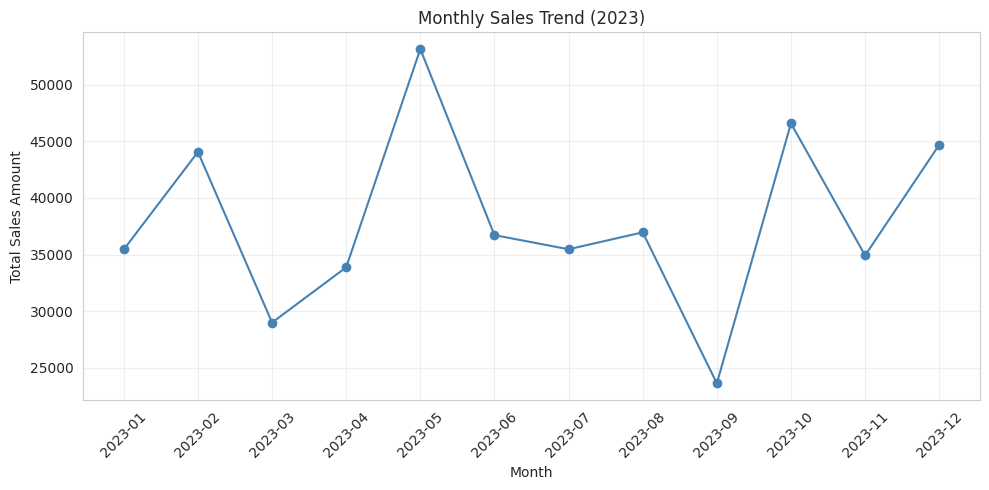

Date
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
Name: Total Amount, dtype: int64


In [29]:
# Created the month and quarter columns
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

df_year = df[df["Date"] < "2024-01-01"]

monthly_sales = df_year.groupby(df_year["Date"].dt.to_period("M"))["Total Amount"].sum()

plt.figure(figsize=(10, 5))
monthly_sales.index = monthly_sales.index.astype(str)
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="steelblue")
plt.title("Monthly Sales Trend (2023)")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(monthly_sales)

Observations:
 Monthly sales fluctuate throughout the year without a consistent trend.
 May had the highest sales (53,150), while September had the lowest (23,620).
 Sales improved in the last quarter, with October (46,580) and December (44,690) performing well.
 Since the data covers only one year, recurring patterns cannot be confirmed, and large orders may have affected sales.
 I excluded 1 January 2024 because it represents only one day and could distort the chart.

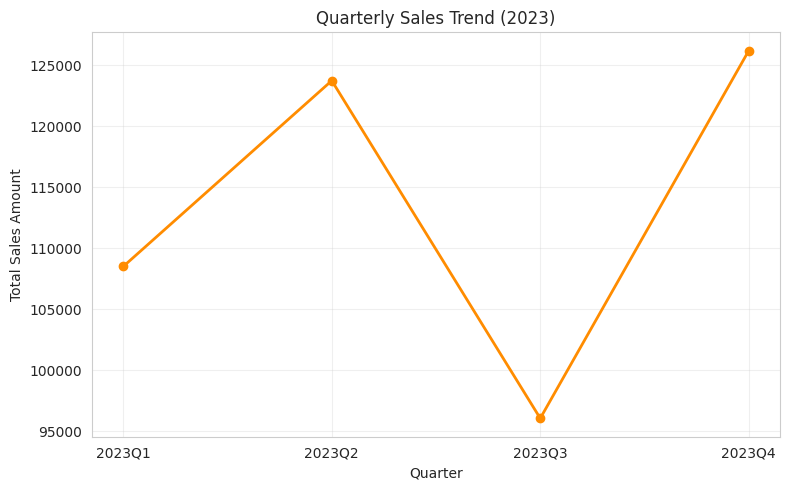

Date
2023Q1    108500
2023Q2    123735
2023Q3     96045
2023Q4    126190
Name: Total Amount, dtype: int64


In [30]:
quarterly_sales = df_year.groupby(df_year["Date"].dt.to_period("Q"))["Total Amount"].sum()
quarterly_sales.index = quarterly_sales.index.astype(str)

plt.figure(figsize=(8, 5))
plt.plot(quarterly_sales.index, quarterly_sales.values, marker="o", color="darkorange", linewidth=2)
plt.title("Quarterly Sales Trend (2023)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales Amount")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(quarterly_sales)

Observations:

- Sales fluctuated across the year, with Q2 growing, Q3 dropping, and Q4 recovering.
- Q4 had the highest sales (126,190), while Q3 had the lowest (96,045).
- The Q3 decline matches the monthly chart, where September had the lowest sales.
- Since the y-axis doesn't start at zero, the differences may look more dramatic than they actually are.
- As the data covers only one year, it's unclear whether the Q3 dip is seasonal or a one-time occurrence.

## 4. Customer Demographics

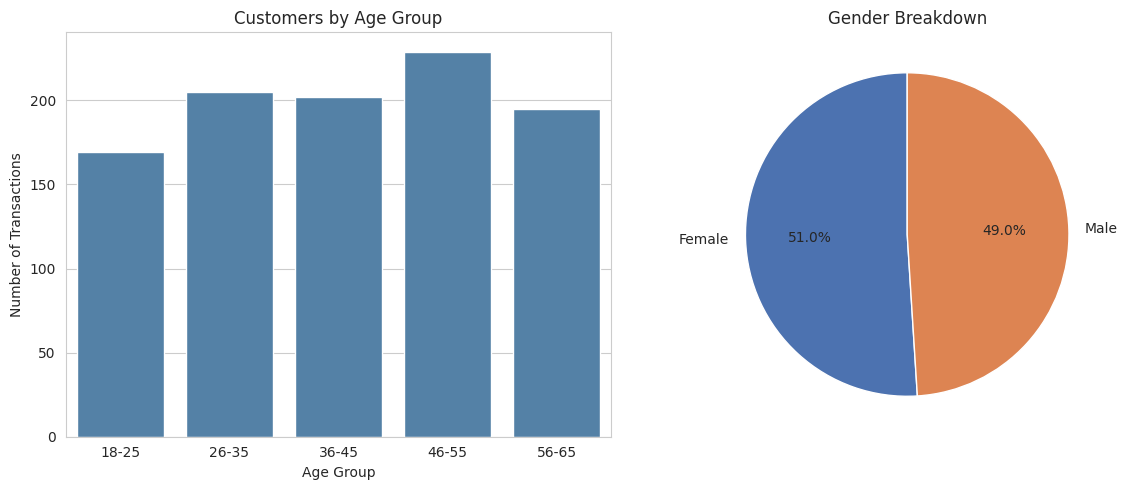

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64

Gender
Female    510
Male      490
Name: count, dtype: int64


In [31]:
# Creating age groups
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

age_counts = df["Age Group"].value_counts().sort_index()
gender_counts = df["Gender"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.barplot(x=age_counts.index, y=age_counts.values, ax=axes[0], color="steelblue")
axes[0].set_title("Customers by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Number of Transactions")


axes[1].pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%",
            colors=["#4c72b0", "#dd8452"], startangle=90)
axes[1].set_title("Gender Breakdown")

plt.tight_layout()
plt.show()

print(age_counts)
print()
print(gender_counts)
# print("Unique customers:", df["Customer ID"].nunique(), "out of", len(df), "transactions")

Observations:

- Transactions are fairly evenly spread across age groups, with ages 46–55 having the most (229) and 18–25 the fewest (169).
- The 18–25 group covers fewer ages, which may explain its lower count.
- Gender split is almost equal, with women accounting for 51% and men 49% of transactions.
- Each transaction has a unique Customer ID, meaning all 1,000 rows represent different customers. There are no repeat customers, so loyalty and repeat buying can't be analysed.
- I'll compare revenue by age group and gender next to see who spends more.

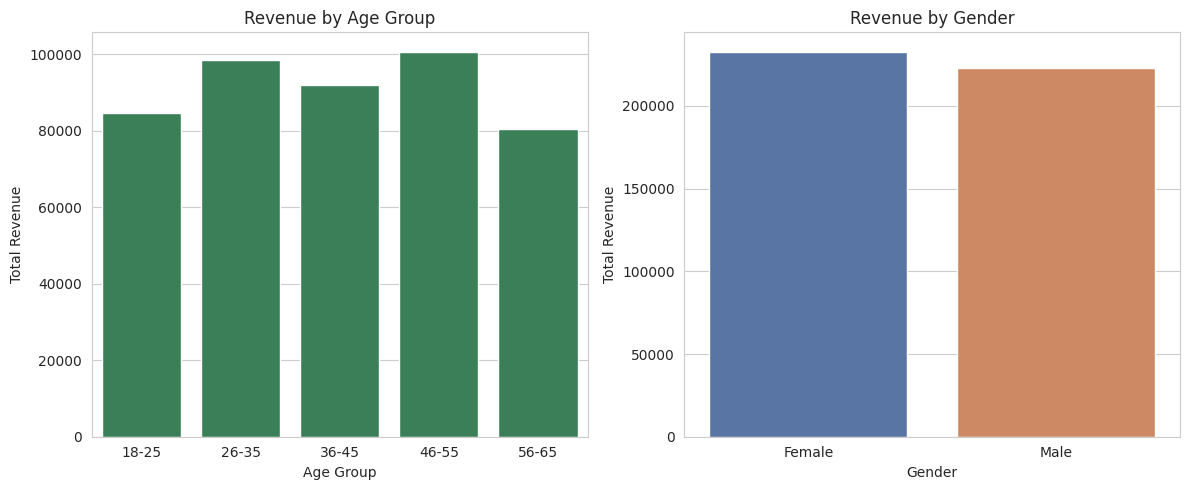

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-65     80410
Name: Total Amount, dtype: int64

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

rev_age = df.groupby("Age Group", observed=True)["Total Amount"].sum()
sns.barplot(x=rev_age.index, y=rev_age.values, ax=axes[0], color="seagreen")
axes[0].set_title("Revenue by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Total Revenue")

rev_gender = df.groupby("Gender")["Total Amount"].sum()
sns.barplot(x=rev_gender.index, y=rev_gender.values, ax=axes[1], palette=["#4c72b0", "#dd8452"], hue=rev_gender.index, legend=False)
axes[1].set_title("Revenue by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Total Revenue")

plt.tight_layout()
plt.show()

print(rev_age)
print()
print(rev_gender)

Observations:

- The 46–55 age group generated the highest revenue (100,690), followed by 26–35 (98,480). The 56–65 group had the lowest (80,410).
- Revenue mostly follows transaction counts, but the 18–25 group has the highest average spend per transaction at around 500.
- Women contributed 232,840 in revenue, while men contributed 223,160, a small difference of around 4%.
- Overall, revenue is fairly evenly distributed across age groups and genders, with no clear dominant group.

## 5. Product Analysis

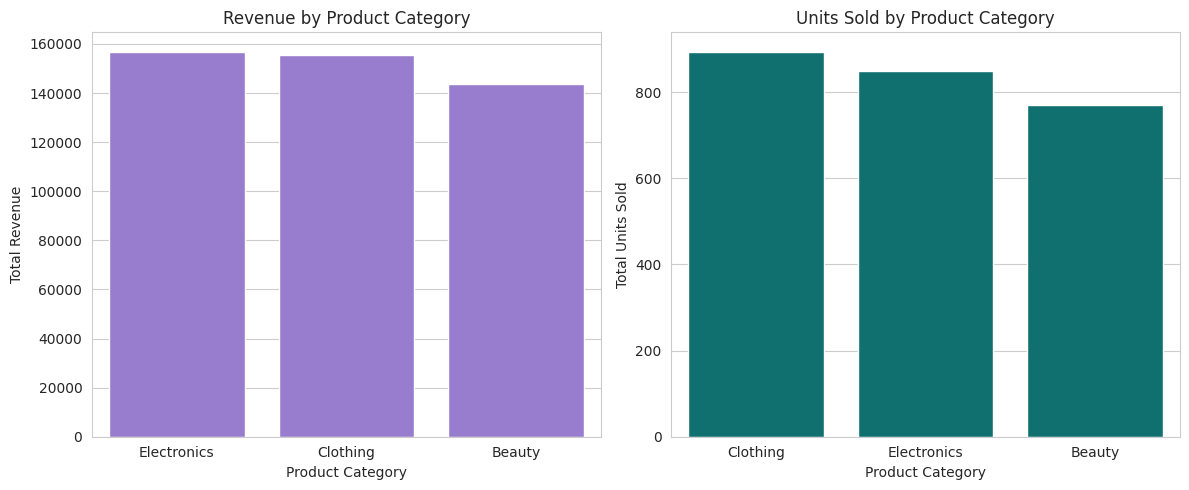

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


In [33]:
cat_rev = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
cat_qty = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=cat_rev.index, y=cat_rev.values, ax=axes[0], color="mediumpurple")
axes[0].set_title("Revenue by Product Category")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Total Revenue")

sns.barplot(x=cat_qty.index, y=cat_qty.values, ax=axes[1], color="teal")
axes[1].set_title("Units Sold by Product Category")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

print(cat_rev)
print()
print(cat_qty)

Observations:

- Electronics generated the highest revenue (156,900), closely followed by Clothing (155,600).
- Beauty had the lowest revenue (143,500) and units sold (771).
- Clothing sold the most units (894), but Electronics earned slightly more, suggesting a higher average item price.
- All three categories contribute around 31–34% of total revenue, so sales are fairly balanced across categories.

Note on "products": This dataset has no product names, only a category and a price per unit. To get a top 10 list, I treated each combination of category and price (for example "Clothing @ 300") as one product. These are stand-ins, not real items.

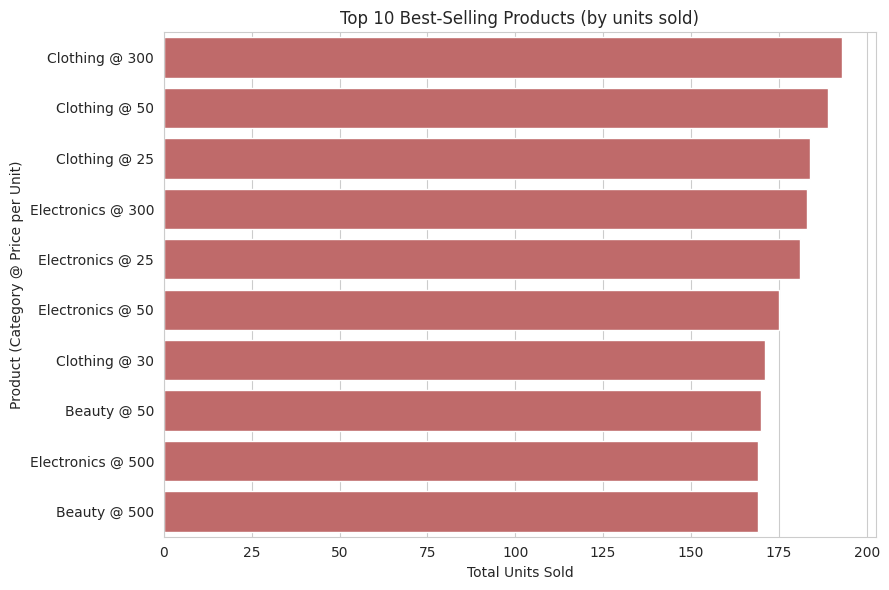

Product
Clothing @ 300       193
Clothing @ 50        189
Clothing @ 25        184
Electronics @ 300    183
Electronics @ 25     181
Electronics @ 50     175
Clothing @ 30        171
Beauty @ 50          170
Electronics @ 500    169
Beauty @ 500         169
Name: Quantity, dtype: int64

Number of distinct category/price combinations: 15


In [34]:
df["Product"] = df["Product Category"] + " @ " + df["Price per Unit"].astype(str)

top_products = (df.groupby("Product")["Quantity"].sum()
                  .sort_values(ascending=False)
                  .head(10))

plt.figure(figsize=(9, 6))
sns.barplot(x=top_products.values, y=top_products.index, color="indianred")
plt.title("Top 10 Best-Selling Products (by units sold)")
plt.xlabel("Total Units Sold")
plt.ylabel("Product (Category @ Price per Unit)")
plt.tight_layout()
plt.show()

print(top_products)
print("\nNumber of distinct category/price combinations:", df["Product"].nunique())

Observations:

- The top 10 items have similar sales, ranging from 169 to 193 units.
- Clothing and Electronics each have four entries, while Beauty has two.
- Cheaper items sell more units, while higher-priced items generate more revenue per sale.
- The differences are small, and the ranking is based on category and price combinations, not actual product names.

## 6. Correlation Analysis

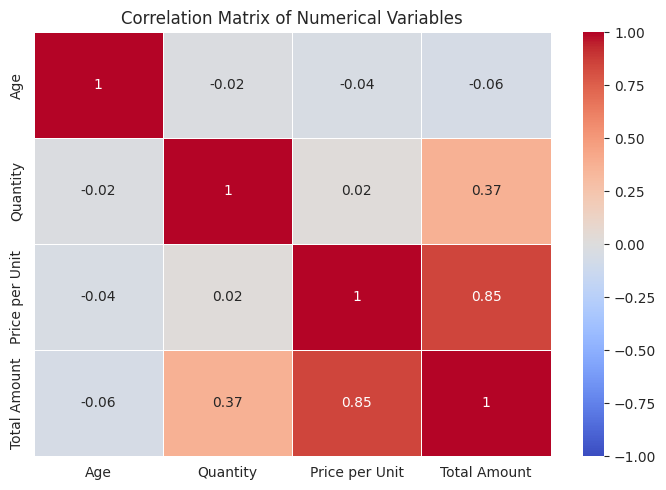

                 Age  Quantity  Price per Unit  Total Amount
Age             1.00     -0.02           -0.04         -0.06
Quantity       -0.02      1.00            0.02          0.37
Price per Unit -0.04      0.02            1.00          0.85
Total Amount   -0.06      0.37            0.85          1.00


In [35]:
corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
corr = df[corr_cols].corr().round(2)

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

print(corr)

Observations:

- Price per Unit has the strongest correlation with Total Amount (0.85), while Quantity has a weaker correlation (0.37). This is expected since total amount depends on both.
- Price affects sales more because it ranges from 25 to 500, while quantity ranges only from 1 to 4.
- Price and Quantity are almost unrelated (0.02), meaning expensive items don't necessarily lead to fewer items being purchased.
- Age has almost no correlation with the other variables, so it doesn't help predict spending or quantity purchased.

## 7. Additional Insight: Spending by Age Group and Category

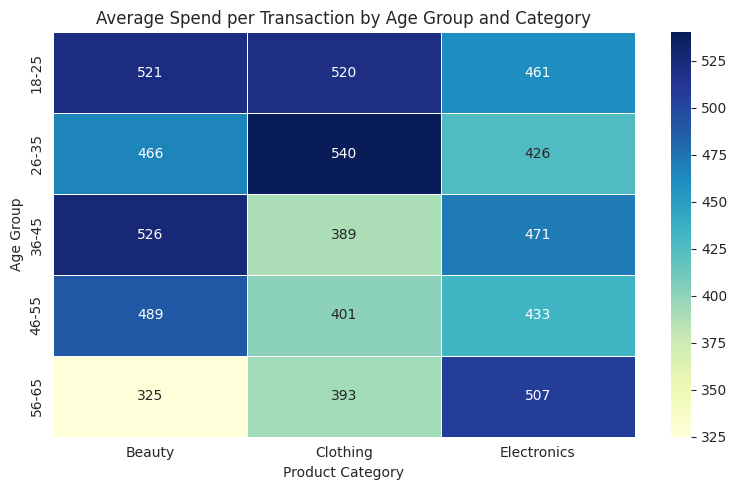

Product Category  Beauty  Clothing  Electronics
Age Group                                      
18-25              521.0     520.0        461.0
26-35              466.0     540.0        426.0
36-45              526.0     389.0        471.0
46-55              489.0     401.0        433.0
56-65              325.0     393.0        507.0


In [36]:
pivot = df.pivot_table(values="Total Amount", index="Age Group",
                       columns="Product Category", aggfunc="mean", observed=True).round(0)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5)
plt.title("Average Spend per Transaction by Age Group and Category")
plt.tight_layout()
plt.show()

print(pivot)

**Observations:**
- The correlation heatmap showed that age has almost no link to spending overall. This chart shows that age does matter once you split by category.
- The 56-65 group spends the least per Beauty purchase (about 325), well below every other age group (466 to 526). The same group spends the most per Electronics purchase (about 507).
- Clothing spend per transaction is higher for ages 18-35 (about 520-540) than for ages 36-65 (about 390-400).
- Each cell has only around 60-80 transactions, and a few expensive purchases can shift an average a lot. These are patterns to look into further, not firm conclusions.

## 8. Conclusion and Recommendations

**Summary of findings**
- Sales for 2023 totalled 456,000 across 1,000 transactions, from 1,000 unique customers.
- Revenue is spread evenly across Electronics (34%), Clothing (34%) and Beauty (32%), and across genders (51% female, 49% male).
- Monthly sales swing a lot. May was the best month (53,150) and September the worst (23,620). Q4 was the strongest quarter and Q3 the weakest.
- Price per unit drives the size of a sale far more than quantity or age.

**Recommendations**
1. **Plan for the Q3 dip.** Q3 sales (96,045) were about 24% below Q4 (126,190), and September was the lowest month. Run promotions or bundle offers in July to September to lift sales in that period. Since there is only one year of data, check next year's figures before treating this as a seasonal pattern.
2. **Target Electronics at customers aged 56-65.** This group spends the most per Electronics purchase (about 507) but the least on Beauty (about 325). Electronics promotions aimed at this group should be a better use of marketing spend than Beauty campaigns.
3. **Push Clothing to customers under 36.** Clothing spend per purchase is about 520-540 for ages 18-35, against about 390-400 for older groups. Younger customers are the best audience for Clothing campaigns.
4. **Grow Beauty with a focus on its weak spot.** Beauty is last on both revenue (143,515) and units (771). Bundling Beauty items with Clothing or Electronics purchases could lift it without needing separate campaigns.
5. **Collect more data.** There are no repeat customers, no product names and only one year of history. Tracking real product names and repeat purchases would allow loyalty analysis and a proper seasonality study.